# Elección de destino en práctica: recursos, cortes y reoptimización local

**Pregunta:** ¿Cómo cambian los límites de capacidad y la reoptimización restringida una programación con destinos?

**Nivel**: 2

**Prerrequisitos**: tema 01, formulación CPIT y configuración del paquete

**Tiempo de lectura**: 38 minutos

## Objetivos





## Preparación

Desde la raíz del repositorio, instala el entorno exacto fijado. Esta celda informa las versiones importadas. El notebook no instala paquetes durante la ejecución.

```bash
pip install oreblocks==0.6.6 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Importa el paquete fijado, las herramientas gráficas y el constructor de instancias de PhaseFlow.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.6
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Datos

El ejemplo usa una veta sintética de 48 bloques, generada con semilla 31 por el constructor MIT de PhaseFlow y OreBlocks 0.6.6. El manifiesto twin-vein comprometido se consulta sólo como contexto de procedencia; el plan se calcula desde una reconstrucción explícita del caso. MineLib no se usa: su resultado Newman1 es un agregado CPIT con destino fijo y condiciones académicas de descarga, no datos redistribuibles por bloque ni un comparador PCPSP.

Reconstruiremos el caso docente documentado en vez de copiar su traza como resultado. La semilla 31 fija el depósito generado. El manifiesto `data/derived/manifests/twin-vein.json` conserva el escenario y los métodos comprometidos; los arreglos de bloques se generan nuevamente mediante el pipeline. Las fuentes tienen roles distintos: el manifiesto aporta procedencia y el generador con semilla es la entrada experimental. Una semilla determinista permite repetir el experimento, pero no representa una verdad geológica. El caso pequeño permite inspeccionar las alternativas de destino y las asignaciones por período. El código reconstruye las dimensiones y el escenario declarados; al experimentar, cambie la semilla explícitamente y registre cada capacidad o supuesto económico que modifique.

Construimos la entrada mediante los contratos tipados `Case` y `Scenario` de PhaseFlow. Las dos filas de recursos representan extracción y procesamiento; sus fracciones son supuestos de capacidad, no límites medidos de una planta. Inspeccionamos el informe contractual antes de entregar la instancia a los métodos de programación.

In [2]:
# Reconstruye la instancia docente con semilla y lee el registro de procedencia comprometido.
case = Case(
    id='nb-destination-vein-4x4x3', category='teaching',
    title_en='Destination lesson', title_es='Leccion de destinos',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(periods=4, discount_rate=0.08,
                      capacity_fraction=(0.70, 0.50),
                      resource_names=('extraccion', 'procesamiento')),
)
instance = build_instance(case)
manifest = json.loads(Path('../../../data/derived/manifests/twin-vein.json').read_text(encoding='utf-8'))
print('contrato aceptado:', instance.report.ok)
print('bloques:', instance.n_blocks, '| recursos:', instance.pcpsp.n_resources,
      '| destinos:', instance.pcpsp.n_destinations)
print('caso de procedencia comprometido:', manifest['case_id'])

contrato aceptado: True
bloques: 48 | recursos: 2 | destinos: 2
caso de procedencia comprometido: twin-vein


## Método

Comenzamos con la relajación continua porque ofrece una referencia superior para todo plan entero factible de la misma formulación PCPSP. El paquete puede devolver tiempos esperados y participaciones por destino, diagnósticos fraccionales. Después generamos un plan factible mediante TopoSort con destinos. Finalmente, la búsqueda local restringida explora vecindarios acotados y cambia períodos y destinos en conjunto. Así se complementan una cota, un método constructivo y un método exacto sobre subproblemas.

El paso de modelado consiste en preservar la economía y los coeficientes de recursos de cada destino desde la creación del bloque hasta la evaluación. Sea z[b,d,t] la asignación del bloque b al período t y al destino d. El valor se descuenta según el período. Cada fila de recursos suma el coeficiente de la alternativa seleccionada, y las restricciones de precedencia se aplican a la extracción sin importar el destino. En el modelo del paquete, `Pcpsp.value` contiene un valor por bloque y destino, mientras `Pcpsp.coef` contiene un vector de recursos por bloque y destino. `to_cpit()` entrega la reducción a destino fijo óptimo: sirve de contexto, pero no reemplaza la elección conjunta.

La primera computación resuelve la relajación LP de PCPSP y conserva sus vectores de solución. Además de la cota objetivo, el resultado puede exponer tiempos esperados de extracción y participaciones fraccionales por destino. Estos valores muestran las preferencias de la relajación, pero no constituyen un plan entero factible. Conservamos estado del solver y dimensiones del modelo para hacer visible la procedencia de la cota. Si el tamaño supera el límite de filas configurado, el paquete puede omitir el LP directo; se informa esa ausencia, nunca se reemplaza por una cifra inventada.

TopoSort con destinos es el método constructivo inicial. Ordena los bloques usando ponderaciones sensibles al destino, revisa los períodos de sus predecesores y luego examina cada alternativa permitida. Para cada destino busca el período más temprano con capacidad restante suficiente. Entre esas colocaciones elige la mayor contribución descontada. La política es determinista para esta entrada fija. Garantiza capacidad al construir el plan, pero no aplica restricciones generales de mezcla, que este caso no declara.

El segundo plan es una reoptimización exacta restringida alrededor del incumbente de TopoSort. `exact_destination_local_search` selecciona un vecindario de bloques y reoptimiza conjuntamente sus períodos y destinos, mientras fija los demás. El modelo es exacto para las variables restringidas; por ello, el plan completo no queda probado óptimo globalmente. Cada movimiento aceptado mejora o conserva el incumbente, de modo que el objetivo final no puede quedar por debajo del inicial. Fijamos semilla, tamaño del vecindario, rondas y límite de tiempo del solver para repetir y acotar el experimento.

El evaluador del plan recalcula por separado el valor descontado y el uso de recursos desde los arreglos de período y destino. Comparamos el VPN del evaluador con el VPN del objeto de método y tabulamos holgura por período. Los arreglos conservan un marcador negativo para los bloques no extraídos. Para un bloque extraído, el ID de destino corresponde a la alternativa declarada por el modelo; no infieras planta o botadero sólo a partir de ley, porque una prueba de valor neto o un umbral puede contradecir la economía almacenada.

Una programación CPIT con destino fijo ofrece una tercera fila de contexto. Usa el valor y los coeficientes de recursos que devuelve la reducción CPIT y no puede decidir entre planta y botadero durante la programación. Su resultado es heurístico para el problema reducido. La relajación PCPSP es una cota para la formulación con elección de destino; la programación CPIT es factible para su propia formulación con coeficientes fijos. Reportar ambos valores permite estudiar flexibilidad del modelo, pero no permite comparar formulaciones distintas usando una única brecha.

La primera figura presenta los dos planes con elección de destino frente a la cota de relajación. Muestra la mejora de la reoptimización restringida y la distancia que queda respecto de la cota. La cota no es un tercer plan y una brecha pequeña no prueba optimalidad global si el método no resolvió el entero completo. La segunda figura separa conteos de planta y botadero por período. Expone el movimiento del corte y la competencia por recursos sin sugerir que el tonelaje sea igual al número de bloques; mantenemos esas unidades diferenciadas.

Interpreta el corte efectivo como consecuencia de la programación, no como un umbral fijo de entrada. El método con destinos puede esperar un bloque para enviarlo a planta o elegir botadero, según qué alternativa tenga capacidad y mayor valor descontado. El corte descriptivo puede no ser monótono entre períodos porque cambian capacidad, precedencia y alternativas disponibles. No define una regla universal de ley y no debe copiarse a otro depósito sin reconstruir sus arreglos económicos.

El experimento también permite ver cómo fallaría una implementación incorrecta. Si se reducen los recursos a un coeficiente fijo por bloque, desaparece el beneficio de elegir destino. Si el evaluador usa el valor de planta para todas las asignaciones, el VPN queda errado. Si un bloque extraído tiene destino -1, el paquete lo rechaza. La puntuación independiente y los arreglos visibles facilitan detectar estos errores, pero no reemplazan el contrato del pipeline, las verificaciones de artefactos ni los tests adversariales para las trazas publicadas.

La búsqueda local tiene tiempo finito y explora vecindarios muestreados; por eso el tiempo y la calidad dependen del presupuesto explícito y de la semilla. Cero movimientos aceptados puede significar que los vecindarios elegidos no ofrecieron una mejora factible dentro del tiempo, no que el método inicial sea óptimo. Una mejora demuestra sólo la existencia de un plan factible mejor. La afirmación de exactitud se limita al subproblema restringido y el resultado final se informa frente a la relajación PCPSP.

In [3]:
# Resuelve la relajación PCPSP para acotar cada programación factible.
relaxation = ob.pcpsp_lp_bound(instance.pcpsp, instance.precedence,
                                max_rows=1500000, time_limit=20,
                                solution=True)
print('estado del LP:', relaxation.status)
print('variables:', relaxation.n_variables, '| filas:', relaxation.n_rows)
print('cota superior PCPSP:', round(relaxation.bound, 2))

estado del LP: optimal
variables: 576 | filas: 1144
cota superior PCPSP: 311484.31


In [4]:
# Construye un plan factible con elecciones conjuntas de período y destino.
destination_plan = ob.destination_toposort(instance.pcpsp,
                                             instance.precedence)
print('metodo:', destination_plan.method)
print('VPN:', round(destination_plan.npv, 2))
print('bloques extraidos:', destination_plan.mined_blocks)

metodo: pcpsp-destination-toposort
VPN: 179593.14
bloques extraidos: 16


In [5]:
# Recalcula valor y uso de recursos desde los dos arreglos de decisión.
scored_npv, resource_use = ob.pcpsp_schedule_value(
    instance.pcpsp, destination_plan.period_of_block,
    destination_plan.destination_of_block)
plant = int(np.sum(destination_plan.destination_of_block == 1))
waste = int(np.sum(destination_plan.destination_of_block == 0))
print('VPN recalculado:', round(scored_npv, 2))
print('bloques a planta:', plant, '| bloques a estéril:', waste)
print('uso de recursos por periodo:', np.round(resource_use, 1))
print('limites de recursos:', np.round(instance.pcpsp.limit, 1))

VPN recalculado: 179593.14
bloques a planta: 8 | bloques a estéril: 8
uso de recursos por periodo: [[10800. 10800. 10800. 10800.]
 [ 5400.  5400.  5400.  5400.]]
limites de recursos: [[13230. 13230. 13230. 13230.]
 [ 6075.  6075.  6075.  6075.]]


El paso 4 usa el plan factible de TopoSort como punto de partida para una nueva resolución exacta restringida. El paquete selecciona vecindarios locales mediante una semilla, resuelve cada subproblema restringido y acepta sólo movimientos que conservan o mejoran el incumbente. Los límites acotados de rondas y tiempo hacen que el notebook sea breve y reproducible; no vuelven exacto al problema completo.

In [6]:
# Mejora el incumbente en vecindarios acotados y reproducibles.
improved_plan = ob.exact_destination_local_search(
    instance.pcpsp, instance.precedence, destination_plan,
    d_max=48, rounds=2, seed=13, time_limit=1.0, mip_gap=0.001)
improved_npv, improved_use = ob.pcpsp_schedule_value(
    instance.pcpsp, improved_plan.period_of_block,
    improved_plan.destination_of_block)
print('VPN inicial:', round(destination_plan.npv, 2))
print('VPN del objeto de busqueda restringida:', round(improved_plan.npv, 2))
print('VPN de busqueda restringida:', round(improved_npv, 2))
print('start bloques:', destination_plan.mined_blocks)
print('restricted-search bloques:', improved_plan.mined_blocks)

VPN inicial: 179593.14
VPN del objeto de busqueda restringida: 237344.67
VPN de busqueda restringida: 237344.67
start bloques: 16
restricted-search bloques: 4


A fixed-destination CPIT schedule provides an explicit formulation contrast. La reducción elige el mejor destino individual de cada bloque antes de programarlo; por eso la programación no puede reasignar la capacidad de planta a medida que avanza el horizonte. Informamos su VPN junto a los valores PCPSP, pero no lo dividimos por la cota PCPSP ni presentamos la comparación como una brecha certificada.

In [7]:
# Resuelve la reducción de destino fijo óptimo sólo como contexto.
fixed_cpit = ob.toposort_schedule(instance.cpit, instance.precedence,
                                  weight='greedy')
print('heurística CPIT con destino fijo:', round(fixed_cpit.npv, 2))
print('PCPSP relaxation:', round(relaxation.bound, 2))
print('PCPSP y CPIT son envolventes de modelos distintos.')

heurística CPIT con destino fijo: 179593.14
PCPSP relaxation: 311484.31
PCPSP y CPIT son envolventes de modelos distintos.


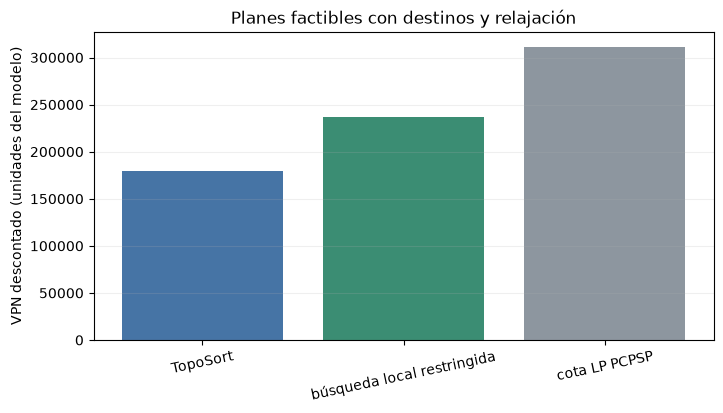

In [8]:
# Compara métodos factibles con la cota de relajación PCPSP.
fig, ax = plt.subplots(figsize=(8, 4))
labels = ['TopoSort', 'búsqueda local restringida', 'cota LP PCPSP']
values = [destination_plan.npv, improved_npv, relaxation.bound]
colors = ['#4674a5', '#3b8d73', '#8d969f']
ax.bar(labels, values, color=colors)
ax.set(title='Planes factibles con destinos y relajación',
       ylabel='VPN descontado (unidades del modelo)')
ax.tick_params(axis='x', rotation=12)
ax.grid(axis='y', alpha=0.2)
plt.show()

Las dos primeras barras representan planes PCPSP factibles; la última es una cota superior LP para la misma formulación con elección de destino. A higher local-search bar is a measured feasible improvement, not a proof that the full mixed-integer model is optimal. Si las barras empatan, la búsqueda acotada de vecindarios no encontró en esta corrida ningún movimiento de mejora aceptado; esto no informa sobre los vecindarios que no visitó. Excluimos el comparador CPIT de este denominador porque su formulación fija el destino.

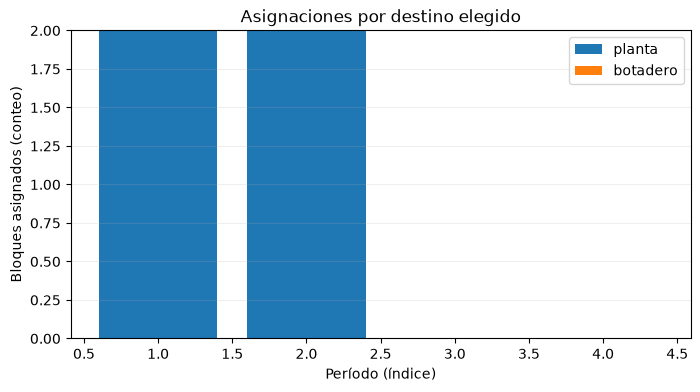

In [9]:
# Grafica conteos de destinos por período del plan final.
fig, ax = plt.subplots(figsize=(8, 4))
plant_counts = [int(np.sum((improved_plan.period_of_block == t) &
                            (improved_plan.destination_of_block == 1)))
                for t in range(instance.pcpsp.n_periods)]
waste_counts = [int(np.sum((improved_plan.period_of_block == t) &
                            (improved_plan.destination_of_block == 0)))
                for t in range(instance.pcpsp.n_periods)]
periods = np.arange(1, instance.pcpsp.n_periods + 1)
ax.bar(periods, plant_counts, label='planta')
ax.bar(periods, waste_counts, bottom=plant_counts, label='botadero')
ax.set(title='Asignaciones por destino elegido',
       xlabel='Período (índice)', ylabel='Bloques asignados (conteo)')
ax.legend()
ax.grid(axis='y', alpha=0.2)
plt.show()

Las barras apiladas muestran cómo cambia por período la mezcla de destinos en la programación mejorada. Cuentan asignaciones, no tonelaje ni valor, y no codifican ley ni uso de recursos; para eso se necesitan la economía de bloques y el gráfico de capacidad anterior. La cantidad de bloques enviados a planta puede disminuir por las precedencias, la capacidad restante o el intercambio de valor. La figura describe sólo esta semilla y este escenario; no es una curva de corte ni una regla para otro depósito.

## Resultados

**Respuesta:** TopoSort con destinos obtuvo 179593.14 y la reoptimización local restringida obtuvo 237344.67; la cota LP PCPSP fue 311484.31. La búsqueda extrae 4 bloques frente a 16 de TopoSort porque el objetivo maximiza valor descontado, no cantidad de bloques. La reoptimización es exacta sólo dentro de vecindarios elegidos; el plan completo no tiene optimalidad certificada.



In [10]:
# Informa los valores usados en la respuesta de Resultados.
print(f'inicial={destination_plan.npv:.2f}; mejorado={improved_npv:.2f}; cota={relaxation.bound:.2f}')

inicial=179593.14; mejorado=237344.67; cota=311484.31


## Resumen

El notebook ejecutó la relajación PCPSP, TopoSort con destinos, reoptimizaciones exactas restringidas y la reducción a destino fijo en una instancia con semilla. Sus resultados responden preguntas diferentes. Conserva etiquetas de formulación, arreglos de destino, reconciliación de recursos y presupuestos del solver al aplicar estos métodos a otros casos.

## Referencias

- Jelvez, Morales y Nancel-Penard (2018), programación de rajos con destinos: https://www.delphoslab.cl/Publicaciones/2018/Jelvez_et_al_MPES2018.pdf
- Constructor de instancias sintéticas y pipeline de PhaseFlow: https://github.com/fsantibanezleal/CAOS_PhaseFlow
- Dossier PhaseFlow: docs/methodologies/09_destinations.md